# Recording fingerprints: what are they made of, and can we project them away?

The main notebook showed that AST embeddings identify a clip's *source* almost perfectly. This notebook asks:

1. **What is the fingerprint made of?** Can the source be read from simple, fault-free properties of a clip —
   its long-term average spectrum, its top frequency band, its length?
2. **Can we project every clip onto a common fingerprint** before the model sees it, so that source cues disappear
   but fault cues survive?

Everything here uses the train split for fitting and the validation split for scoring. The test split is not touched.
Classifiers are logistic regressions on frozen features, so results are deterministic.

## 1. Setup and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio.functional as AF
from huggingface_hub import snapshot_download
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import ASTFeatureExtractor, ASTModel

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "kwerimoto"
RESULTS_DIR = ROOT / "results"
CACHE_DIR = RESULTS_DIR / "cache"
FIG_DIR = RESULTS_DIR / "figures"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
LABELS = ["healthy", "engine_knock", "misfire"]
HEALTHY, KNOCK, MISFIRE = 0, 1, 2
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_FRAMES, N_MELS = 1024, 128

snapshot_download("rayyyyy007/kwerimoto-engine-sounds", repo_type="dataset", local_dir=DATA_DIR)
manifest = pd.read_csv(DATA_DIR / "manifest.csv")
y = manifest["label"].map({name: i for i, name in enumerate(LABELS)}).to_numpy()
source = manifest["source_dataset"].to_numpy()
tr = manifest.index[manifest["split"] == "train"].to_numpy()
va = manifest.index[manifest["split"] == "validation"].to_numpy()

waveforms = [sf.read(DATA_DIR / f, dtype="float32")[0] for f in manifest["file_name"]]
# Number of real (non-padding) spectrogram frames per clip: 25 ms windows, 10 ms hop.
n_frames = np.array([min(MAX_FRAMES, 1 + (len(w) - 400) // 160) for w in waveforms])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1074 files:   0%|          | 0/1074 [00:00<?, ?it/s]

In [2]:
feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_ID)
ast = ASTModel.from_pretrained(MODEL_ID).to(DEVICE).eval()


def spectrograms(audios):
    """AST input: log-mel spectrogram, 1024 frames x 128 bands, standardised by AST's AudioSet statistics."""
    return np.concatenate([
        feature_extractor(audios[i:i + 64], sampling_rate=16_000, return_tensors="np")["input_values"]
        for i in range(0, len(audios), 64)
    ]).astype(np.float32)


inputs_path = CACHE_DIR / "ast_input_values.npy"  # shared with the main notebook
if inputs_path.exists():
    inputs = np.load(inputs_path).astype(np.float32)
else:
    inputs = spectrograms(waveforms)
    np.save(inputs_path, inputs.astype(np.float16))
PAD_VALUE = float(inputs[int(n_frames.argmin()), -1, 0])  # what the extractor writes into padding frames


@torch.inference_mode()
def embed(spec, name=None):
    """Frozen AST clip embeddings for an array of spectrograms; cached on disk when `name` is given."""
    path = CACHE_DIR / f"fingerprint_{name}.npy" if name else None
    if path is not None and path.exists():
        return np.load(path)
    out = np.concatenate([
        ast(torch.from_numpy(spec[i:i + 32]).to(DEVICE)).pooler_output.float().cpu().numpy()
        for i in range(0, len(spec), 32)
    ])
    if path is not None:
        np.save(path, out)
    return out

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 2. What is the fingerprint made of?

For each clip we compute properties that describe the *recording*, not the engine's behaviour over time:

- **Average spectrum** — the mean level of each of the 128 frequency bands over the clip. A microphone, codec or
  resampler acts like a fixed filter, which shows up here as a constant offset per band. It also contains real
  engine information (an engine's tone), so it is not purely nuisance.
- **Top band only** — the average level of the bands above 7 kHz, where resampling and codec filters leave traces.
- **Clip length** — one number.

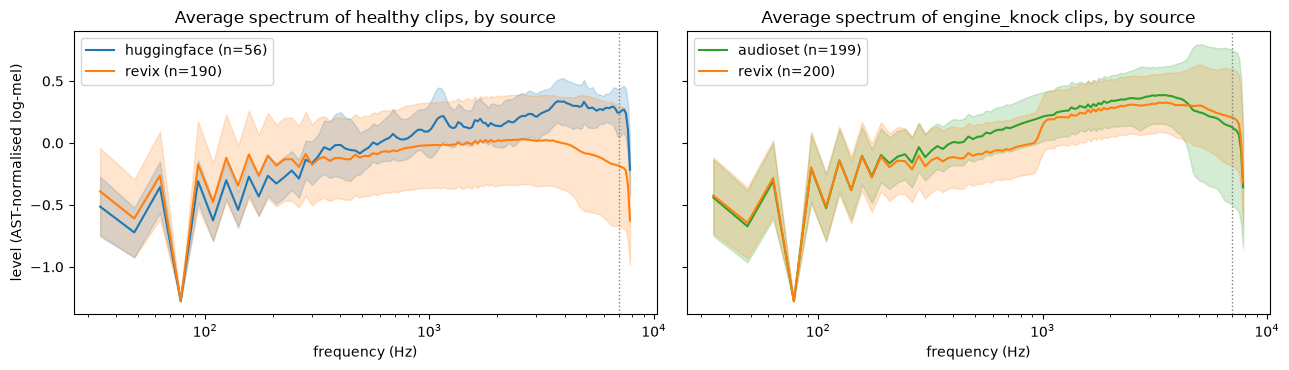

In [3]:
# Centre frequency of each mel band (Kaldi mel scale, 20 Hz to 8 kHz).
mel = lambda f: 1127.0 * np.log1p(f / 700.0)
mel_edges = np.linspace(mel(20.0), mel(8000.0), N_MELS + 2)
band_hz = 700.0 * np.expm1(mel_edges[1:-1] / 1127.0)

avg_spectrum = np.stack([inputs[i, :n].mean(0) for i, n in enumerate(n_frames)])
band_spread = np.stack([inputs[i, :n].std(0) for i, n in enumerate(n_frames)])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
panels = {"healthy": [("huggingface", "tab:blue"), ("revix", "tab:orange")],
          "engine_knock": [("audioset", "tab:green"), ("revix", "tab:orange")]}
for ax, (label, groups) in zip(axes, panels.items()):
    for src, color in groups:
        rows = tr[(manifest.loc[tr, "label"] == label) & (source[tr] == src)]
        mean, std = avg_spectrum[rows].mean(0), avg_spectrum[rows].std(0)
        ax.plot(band_hz, mean, color=color, label=f"{src} (n={len(rows)})")
        ax.fill_between(band_hz, mean - std, mean + std, color=color, alpha=0.2)
    ax.set(title=f"Average spectrum of {label} clips, by source", xlabel="frequency (Hz)", xscale="log")
    ax.axvline(7000, color="grey", ls=":", lw=1)
    ax.legend()
axes[0].set_ylabel("level (AST-normalised log-mel)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fingerprint_spectra.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
def fit_predict(F_train, t_train, F_val):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    return clf.fit(F_train, t_train).predict_proba(F_val)


def source_probe(F, label, F_train=None, rows_train=tr):
    """Balanced accuracy at telling the two sources of one class apart (0.5 = chance)."""
    F_train = F if F_train is None else F_train
    rtr, rva = rows_train[y[rows_train] == label], va[y[va] == label]
    proba = fit_predict(F_train[rtr], source[rtr], F[rva])
    classes = np.unique(source[rtr])
    return balanced_accuracy_score(source[rva], classes[proba.argmax(1)])


def fault_scores(F, F_train=None, rows_train=tr):
    """3-class fault classifier on features F: fault recall and healthy false-alarm rate on validation."""
    F_train = F if F_train is None else F_train
    proba = fit_predict(F_train[rows_train], y[rows_train], F[va])
    pred = proba.argmax(1)
    recall = recall_score(y[va], pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {"fault recall": recall[1:].mean(), "false alarm": (pred[y[va] == HEALTHY] != HEALTHY).mean()}, proba


top = band_hz >= 7000
duration = n_frames[:, None].astype(np.float32)
E_original = embed(inputs, "original")
feature_sets = {
    "clip length (1 number)": duration,
    f"top band only, >= 7 kHz ({top.sum()} bands)": avg_spectrum[:, top],
    f"below 7 kHz only ({(~top).sum()} bands)": avg_spectrum[:, ~top],
    "average spectrum (128 bands)": avg_spectrum,
    "average spectrum + per-band spread": np.hstack([avg_spectrum, band_spread]),
    "AST embedding (768 numbers)": E_original,
}
anatomy = pd.DataFrame({
    name: {"source probe | healthy": source_probe(F, HEALTHY),
           "source probe | knock": source_probe(F, KNOCK),
           **fault_scores(F)[0]}
    for name, F in feature_sets.items()
}).T.round(3)
anatomy.to_csv(RESULTS_DIR / "fingerprint_anatomy.csv")
anatomy

,source probe | healthy,source probe | knock,fault recall,false alarm
clip length (1 number),0.438,0.756,0.494,1.000
"top band only, >= 7 kHz (6 bands)",0.617,0.523,0.448,0.692
below 7 kHz only (122 bands),0.962,0.767,0.765,0.365
average spectrum (128 bands),0.962,0.767,0.770,0.385
average spectrum + per-band spread,0.988,0.814,0.770,0.288
AST embedding (768 numbers),1.000,0.907,0.770,0.192


**Result (draft):**

- **The average spectrum alone gives the source away for healthy clips: 96 %** (Hugging Face vs Revix), with no
  timing information at all. For knocks it is weaker (77 %).
- **The top band is not the culprit.** Bands above 7 kHz identify the source barely better than chance (62 % / 52 %),
  so the "different resampling roll-off" hypothesis from the main notebook is **not supported**; the information sits
  below 7 kHz.
- **Clip length** separates the two knock sources 76 % of the time (AudioSet clips are ~10 s, Revix clips vary).
- The average spectrum predicts the *fault label* nearly as well as the AST embedding does (fault recall 0.77 for
  both, though with twice the false alarms). Because the average spectrum mixes recording colour with genuine engine
  tone, this does not prove the label is predicted from the recording — but it shows how little of the benchmark
  requires listening to what the engine does over time.

Numbers here use logistic regression, so the AST row differs slightly from the main notebook's baseline (0.82).

## 3. Projecting clips onto a common fingerprint

Each projection is applied to the spectrogram (or waveform) **before** the frozen AST model, needs no source
labels, and could be applied identically to a new recording from a phone.

| Projection | What it does | Cue it targets |
|---|---|---|
| `original` | nothing | — |
| `eq` | shifts every band so the clip's average spectrum equals the training-set average | fixed filters: microphone, codec, resampler |
| `eq+var` | `eq`, and also rescales each band's spread to the training-set average | level-dependent processing (compression, noise suppression) |
| `loop` | repeats the clip to fill the 10 s window instead of padding with silence | clip length |
| `lowpass` | resamples 16 → 12 → 16 kHz so every clip gets the same roll-off at 6 kHz | resampling / codec traces near the top of the band |
| `all` | `lowpass`, then `eq+var`, then `loop` | all of the above |
| `eq-augment` | training-time alternative: train on copies with random smooth EQ curves, test on unmodified clips | teaches the classifier to ignore fixed filters |

`eq` removes real engine tone along with the recording colour, so some loss of fault information is expected —
the question is how the trade-off comes out.

In [5]:
def project(spec, frames, equalise=False, match_spread=False, loop=False, ref_mean=None, ref_std=None):
    out = np.full_like(spec, PAD_VALUE)
    for i, n in enumerate(frames):
        clip = spec[i, :n]
        if equalise:
            centred = clip - clip.mean(0)
            if match_spread:
                centred = centred / (clip.std(0) + 1e-3) * ref_std
            clip = centred + ref_mean
        if loop:
            clip = np.tile(clip, (MAX_FRAMES // n + 1, 1))[:MAX_FRAMES]
        out[i, :len(clip)] = clip
    return out


def reference(spec, frames):
    """Common fingerprint: the average per-band mean and spread over training clips."""
    return (np.mean([spec[i, :frames[i]].mean(0) for i in tr], 0),
            np.mean([spec[i, :frames[i]].std(0) for i in tr], 0))


ref_mean, ref_std = reference(inputs, n_frames)

lowpassed = [AF.resample(AF.resample(torch.from_numpy(w), 16_000, 12_000), 12_000, 16_000).numpy() for w in waveforms]
inputs_lp = spectrograms(lowpassed)
frames_lp = np.array([min(MAX_FRAMES, 1 + (len(w) - 400) // 160) for w in lowpassed])
ref_mean_lp, ref_std_lp = reference(inputs_lp, frames_lp)

embeddings = {
    "original": E_original,
    "eq": embed(project(inputs, n_frames, equalise=True, ref_mean=ref_mean), "eq"),
    "eq+var": embed(project(inputs, n_frames, equalise=True, match_spread=True,
                            ref_mean=ref_mean, ref_std=ref_std), "eq_var"),
    "loop": embed(project(inputs, n_frames, loop=True), "loop"),
    "lowpass": embed(inputs_lp, "lowpass"),
    "all": embed(project(inputs_lp, frames_lp, equalise=True, match_spread=True, loop=True,
                         ref_mean=ref_mean_lp, ref_std=ref_std_lp), "all"),
}

In [6]:
# Training-time alternative: random smooth EQ curves, sized like the real clip-to-clip variation in average spectrum.
N_COPIES, N_CONTROL = 4, 6
eq_sigma = float(avg_spectrum[tr].std(0).mean())
rng = np.random.default_rng(SEED)


def random_eq(spec, frames):
    out = spec.copy()
    for i, n in enumerate(frames):
        curve = np.interp(np.arange(N_MELS), np.linspace(0, N_MELS - 1, N_CONTROL), rng.normal(0, eq_sigma, N_CONTROL))
        out[i, :n] += curve.astype(np.float32)
    return out


aug_path = CACHE_DIR / "fingerprint_eq_augment.npy"
if aug_path.exists():
    E_aug = np.load(aug_path)
else:
    E_aug = np.concatenate([embed(random_eq(inputs[tr], n_frames[tr])) for _ in range(N_COPIES)])
    np.save(aug_path, E_aug)

# Rows of the augmented training set: all clips' original embeddings, followed by N_COPIES augmented train copies.
E_aug_train = np.concatenate([E_original, E_aug])
aug_rows = np.concatenate([tr, len(E_original) + np.arange(len(E_aug))])
y = np.concatenate([y, np.tile(y[tr], N_COPIES)])            # extend labels/sources to cover the extra rows
source = np.concatenate([source, np.tile(source[tr], N_COPIES)])
print(f"eq-augment: sigma = {eq_sigma:.3f}, {len(aug_rows)} training rows")

eq-augment: sigma = 0.318, 3605 training rows


### How each projection is scored

- **Source probe** (lower is better, 0.5 = chance): can a fresh classifier still tell the two sources of a class apart?
- **Fault recall / false alarm**: the usual 3-class validation metrics.
- **Within-source AUC**: fault vs healthy with the source held fixed (as in the main notebook).
- **Confounded → clean** (the key test): train knock-vs-healthy using *only* AudioSet knocks and Hugging Face healthy
  clips — a training set where source and label are perfectly confounded — then test on Revix knocks vs Revix
  healthy, where source cannot help. A model that learned the source scores near 0.5; a model that learned the
  knock scores high. ± is a bootstrap standard deviation over validation clips.
- **Revix → other sources**: train on Revix only, test on AudioSet knocks vs Hugging Face healthy.

In [7]:
def transfer_auc(F, train_mask, test_mask, F_train=None, rows_train=tr, n_boot=1000):
    """Train knock-vs-healthy on one set of sources, report ROC AUC on another (with bootstrap std)."""
    F_train = F if F_train is None else F_train
    rtr, rva = rows_train[train_mask(rows_train)], va[test_mask(va)]
    score = fit_predict(F_train[rtr], y[rtr] == KNOCK, F[rva])[:, 1]
    target = y[rva] == KNOCK
    boot_rng = np.random.default_rng(SEED)
    boots = []
    for _ in range(n_boot):
        idx = boot_rng.integers(0, len(rva), len(rva))
        if target[idx].min() != target[idx].max():
            boots.append(roc_auc_score(target[idx], score[idx]))
    return roc_auc_score(target, score), float(np.std(boots))


confounded = lambda r: ((source[r] == "audioset") & (y[r] == KNOCK)) | ((source[r] == "huggingface") & (y[r] == HEALTHY))
revix_only = lambda r: (source[r] == "revix") & np.isin(y[r], [HEALTHY, KNOCK])


def score_projection(F, F_train=None, rows_train=tr):
    kw = {"F_train": F_train, "rows_train": rows_train}
    faults, proba = fault_scores(F, **kw)
    within = {}
    for name, (src, fault) in {"AUC knock | Revix": ("revix", KNOCK), "AUC misfire | HF": ("huggingface", MISFIRE)}.items():
        rows = (source[va] == src) & np.isin(y[va], [HEALTHY, fault])
        within[name] = roc_auc_score(y[va][rows] == fault, proba[rows, fault])
    c2c, c2c_sd = transfer_auc(F, confounded, revix_only, **kw)
    r2o, r2o_sd = transfer_auc(F, revix_only, confounded, **kw)
    return {"source probe | healthy": source_probe(F, HEALTHY, **kw), "source probe | knock": source_probe(F, KNOCK, **kw),
            **faults, **within,
            "confounded → clean": c2c, "± (c→c)": c2c_sd, "Revix → other": r2o, "± (R→o)": r2o_sd}


results = pd.DataFrame({name: score_projection(E) for name, E in embeddings.items()}).T
results.loc["eq-augment"] = score_projection(E_original, F_train=E_aug_train, rows_train=aug_rows)
results.to_csv(RESULTS_DIR / "fingerprint_projections.csv")
results.round(3)

,source probe | healthy,source probe | knock,fault recall,false alarm,AUC knock | Revix,AUC misfire | HF,confounded → clean,± (c→c),Revix → other,± (R→o)
original,1.0,0.907,0.770,0.192,0.862,0.849,0.415,0.065,0.455,0.075
eq,1.0,0.930,0.794,0.173,0.862,0.818,0.510,0.066,0.523,0.080
eq+var,1.0,0.872,0.757,0.192,0.780,0.880,0.364,0.062,0.333,0.080
loop,1.0,0.919,0.813,0.212,0.858,0.828,0.575,0.062,0.566,0.085
lowpass,1.0,0.919,0.762,0.135,0.885,0.859,0.375,0.065,0.355,0.074
all,1.0,0.930,0.759,0.173,0.731,0.839,0.393,0.065,0.475,0.087
eq-augment,1.0,0.919,0.788,0.192,0.868,0.885,0.306,0.060,0.366,0.083


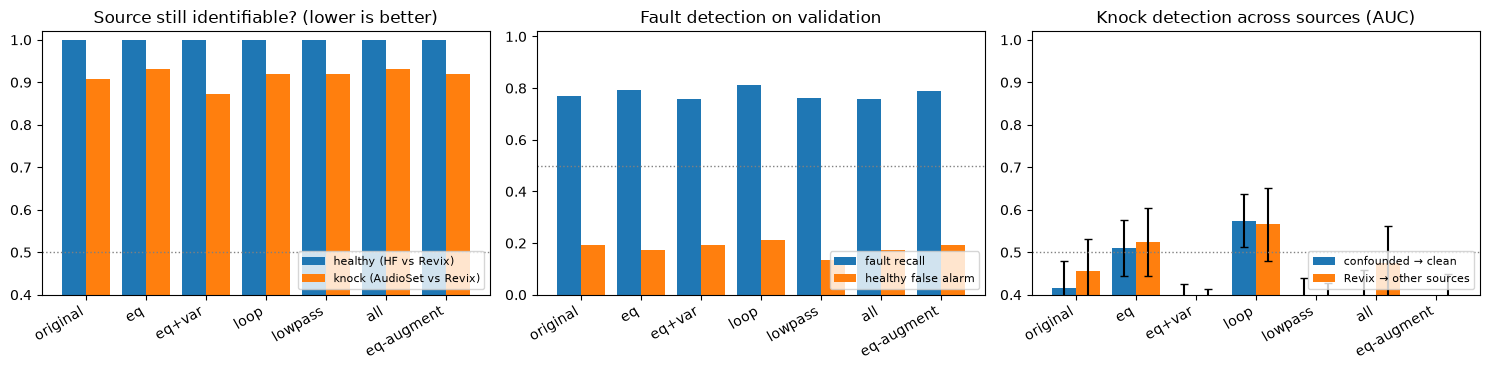

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(len(results))
axes[0].bar(x - 0.2, results["source probe | healthy"], 0.4, label="healthy (HF vs Revix)")
axes[0].bar(x + 0.2, results["source probe | knock"], 0.4, label="knock (AudioSet vs Revix)")
axes[0].set(title="Source still identifiable? (lower is better)", ylim=(0.4, 1.02))
axes[1].bar(x - 0.2, results["fault recall"], 0.4, label="fault recall")
axes[1].bar(x + 0.2, results["false alarm"], 0.4, label="healthy false alarm")
axes[1].set(title="Fault detection on validation", ylim=(0, 1.02))
axes[2].bar(x - 0.2, results["confounded → clean"], 0.4, yerr=results["± (c→c)"], capsize=3, label="confounded → clean")
axes[2].bar(x + 0.2, results["Revix → other"], 0.4, yerr=results["± (R→o)"], capsize=3, label="Revix → other sources")
axes[2].set(title="Knock detection across sources (AUC)", ylim=(0.4, 1.02))
for ax in axes:
    ax.axhline(0.5, color="grey", ls=":", lw=1)
    ax.set_xticks(x, results.index, rotation=30, ha="right")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fingerprint_projections.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. What we found (draft)

**The projections did not work — and the way they failed is informative.**

1. **No projection removed the fingerprint.** After `eq`, every clip has *exactly* the same average spectrum, yet
   AST still tells Hugging Face healthy clips from Revix healthy clips with 100 % accuracy, and knock sources with
   ~90 %. Matching per-band spread, equalising the top band and removing the length cue changed nothing. So the
   fingerprint is **not just a fixed filter** (microphone or codec colour). What remains is time-varying: how the
   engines and surroundings actually sound, or dynamic processing. With this dataset we cannot tell those apart,
   because each "source" is also a different collection of vehicles and recording situations.
2. **Knock detection does not transfer between sources at all.** Trained on AudioSet knocks vs Hugging Face healthy
   clips, the model scores **0.42 AUC** on Revix knocks vs Revix healthy — no better than a coin flip. The reverse
   direction is 0.46. No projection moved either number clearly away from 0.5 (the best, `loop`, reaches
   0.58 ± 0.06). A model that had learned "what a knock sounds like" would transfer; this one learned something
   specific to each source. This also means the real and the synthetic (overlaid) knocks do not look like the same
   thing to the model.
3. **Fault metrics barely moved** under any projection (fault recall 0.76–0.81), so equalisation is at least cheap
   and harmless — but here it buys nothing measurable.

**Caveats.** Validation sets are small (the transfer tests use 83 and 55 clips; ± is one bootstrap standard
deviation), a single frozen model was tested, and the within-source knock test relies on overlaid knocks.

**Implications.** For this kind of data, input normalisation cannot substitute for collecting every class under the
same conditions. To study *microphone* fingerprints specifically, the next step is a dataset where the same sound is
recorded by several labelled devices (e.g. DCASE TAU Urban Acoustic Scenes Mobile, MIMII DG, ToyADMOS2): there the
fixed-filter model should hold, and `eq`-style projection can be tested fairly. Other untested ideas: erasing the
source in embedding space (LEACE), features built on rhythm rather than tone (modulation spectra), and passing all
clips through one codec.